In [6]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import confusion_matrix, classification_report
from scipy import stats

from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier

In [7]:
pd.reset_option('display.max_rows')

In [8]:
data=pd.read_csv(r"C:\Users\user\Downloads\application.csv")
data

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.0220,0.0198,0.0,0.0000,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.0000,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.0790,0.0554,0.0,0.0000,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.0100,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [9]:
pd.set_option('display.max_columns',None)

In [10]:
data.describe(include='all')

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511,307511,307511,307511,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,306219,307511,307511,307511,307511,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,104582.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,211120,307509.000000,307511.000000,307511.000000,307511,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511,134133.000000,3.068510e+05,246546.000000,151450.00000,127568.000000,157504.000000,103023.000000,92646.000000,143620.000000,152683.000000,154491.000000,98869.000000,124921.000000,97312.000000,153161.000000,93997.000000,137829.000000,151450.000000,127568.000000,157504.000000,103023.000000,92646.000000,143620.000000,152683.000000,154491.000000,98869.000000,124921.000000,97312.000000,153161.000000,93997.000000,137829.000000,151450.000000,127568.000000,157504.000000,103023.000000,92646.000000,143620.000000,152683.000000,154491.000000,98869.000000,124921.000000,97312.000000,153161.000000,93997.000000,137829.000000,97216,153214,159080.000000,151170,161756,306490.000000,306490.000000,306490.000000,306490.000000,307510.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.00000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
unique,NaN,NaN,2,3,2,2,NaN,NaN,NaN,NaN,NaN,7,8,5,6,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18,NaN,NaN,NaN,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Na

In [11]:
pd.set_option('display.max_rows',None)

In [12]:
data.isnull().sum()

SK_ID_CURR                           0
TARGET                               0
NAME_CONTRACT_TYPE                   0
CODE_GENDER                          0
FLAG_OWN_CAR                         0
FLAG_OWN_REALTY                      0
CNT_CHILDREN                         0
AMT_INCOME_TOTAL                     0
AMT_CREDIT                           0
AMT_ANNUITY                         12
AMT_GOODS_PRICE                    278
NAME_TYPE_SUITE                   1292
NAME_INCOME_TYPE                     0
NAME_EDUCATION_TYPE                  0
NAME_FAMILY_STATUS                   0
NAME_HOUSING_TYPE                    0
REGION_POPULATION_RELATIVE           0
DAYS_BIRTH                           0
DAYS_EMPLOYED                        0
DAYS_REGISTRATION                    0
DAYS_ID_PUBLISH                      0
OWN_CAR_AGE                     202929
FLAG_MOBIL                           0
FLAG_EMP_PHONE                       0
FLAG_WORK_PHONE                      0
FLAG_CONT_MOBILE         

In [13]:
for i in data.columns:
    if data[i].isnull().sum()/len(data)>0.1:
        data=data.drop(i,axis=1)

In [14]:
pd.set_option('display.max_rows',None)

In [15]:
data.isnull().sum()

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
FLAG_OWN_REALTY                   0
CNT_CHILDREN                      0
AMT_INCOME_TOTAL                  0
AMT_CREDIT                        0
AMT_ANNUITY                      12
AMT_GOODS_PRICE                 278
NAME_TYPE_SUITE                1292
NAME_INCOME_TYPE                  0
NAME_EDUCATION_TYPE               0
NAME_FAMILY_STATUS                0
NAME_HOUSING_TYPE                 0
REGION_POPULATION_RELATIVE        0
DAYS_BIRTH                        0
DAYS_EMPLOYED                     0
DAYS_REGISTRATION                 0
DAYS_ID_PUBLISH                   0
FLAG_MOBIL                        0
FLAG_EMP_PHONE                    0
FLAG_WORK_PHONE                   0
FLAG_CONT_MOBILE                  0
FLAG_PHONE                        0
FLAG_EMAIL                        0
CNT_FAM_MEMBERS             

In [16]:
data.drop('SK_ID_CURR',axis=1,inplace=True)

In [17]:
data_lr=data.copy()

In [18]:
for i in data_lr.columns:
    if data_lr[i].dtype=='object':
        data_lr[i]=data_lr[i].fillna(data_lr[i].mode()[0])
    else:
        data_lr[i]=data_lr[i].fillna(data_lr[i].mean())

In [14]:
data_lr.isnull().sum()

TARGET                         0
NAME_CONTRACT_TYPE             0
CODE_GENDER                    0
FLAG_OWN_CAR                   0
FLAG_OWN_REALTY                0
CNT_CHILDREN                   0
AMT_INCOME_TOTAL               0
AMT_CREDIT                     0
AMT_ANNUITY                    0
AMT_GOODS_PRICE                0
NAME_TYPE_SUITE                0
NAME_INCOME_TYPE               0
NAME_EDUCATION_TYPE            0
NAME_FAMILY_STATUS             0
NAME_HOUSING_TYPE              0
REGION_POPULATION_RELATIVE     0
DAYS_BIRTH                     0
DAYS_EMPLOYED                  0
DAYS_REGISTRATION              0
DAYS_ID_PUBLISH                0
FLAG_MOBIL                     0
FLAG_EMP_PHONE                 0
FLAG_WORK_PHONE                0
FLAG_CONT_MOBILE               0
FLAG_PHONE                     0
FLAG_EMAIL                     0
CNT_FAM_MEMBERS                0
REGION_RATING_CLIENT           0
REGION_RATING_CLIENT_W_CITY    0
WEEKDAY_APPR_PROCESS_START     0
HOUR_APPR_

In [369]:

epsilon = 1e-6  

for i in data_lr.columns:
    if i != 'TARGET':
        if data_lr[i].dtype != object:
      
            q1 = data_lr[i].quantile(0.25)
            q2 = data_lr[i].quantile(0.5)
            q3 = data_lr[i].quantile(0.75)

            ranges = [-np.inf, q1, q2, q3, np.inf]
            data_lr['category_' + i] = pd.cut(data_lr[i], bins=ranges, duplicates='drop')

            grouped = data_lr.groupby(['category_' + i, 'TARGET'])['TARGET'].count().unstack(fill_value=0).reset_index()

    
            grouped[0] = grouped[0].replace(0, epsilon)
            grouped[1] = grouped[1].replace(0, epsilon)


            grouped['positive_prop'] = grouped[0] / grouped[0].sum()
            grouped['negative_prop'] = grouped[1] / grouped[1].sum()


            grouped['woe'] = np.log(grouped['positive_prop'] / grouped['negative_prop'])

            grouped.rename(columns={'woe': i + '_woe'}, inplace=True)

            data_lr = data_lr.merge(grouped[['category_' + i, i + '_woe']], how='left', on='category_' + i)

        else:
            grouped = data_lr.groupby([i, 'TARGET'])['TARGET'].count().unstack(fill_value=0).reset_index()

            grouped[0] = grouped[0].replace(0, epsilon)
            grouped[1] = grouped[1].replace(0, epsilon)

            grouped['positive_prop'] = grouped[0] / grouped[0].sum()
            grouped['negative_prop'] = grouped[1] / grouped[1].sum()

            grouped['woe'] = np.log(grouped['positive_prop'] / grouped['negative_prop'])

            grouped.rename(columns={'woe': i + '_woe'}, inplace=True)

            data_lr = data_lr.merge(grouped[[i, i + '_woe']], how='left', on=i)


C:\Users\user\AppData\Local\Temp\ipykernel_18084\3875558559.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = data_lr.groupby(['category_' + i, 'TARGET'])['TARGET'].count().unstack(fill_value=0).reset_index()
C:\Users\user\AppData\Local\Temp\ipykernel_18084\3875558559.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = data_lr.groupby(['category_' + i, 'TARGET'])['TARGET'].count().unstack(fill_value=0).reset_index()
C:\Users\user\AppData\Local\Temp\ipykernel_18084\3875558559.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future versio

In [370]:
data_lr.isnull().sum()

TARGET                                  0
NAME_CONTRACT_TYPE                      0
CODE_GENDER                             0
FLAG_OWN_CAR                            0
FLAG_OWN_REALTY                         0
CNT_CHILDREN                            0
AMT_INCOME_TOTAL                        0
AMT_CREDIT                              0
AMT_ANNUITY                             0
AMT_GOODS_PRICE                         0
NAME_TYPE_SUITE                         0
NAME_INCOME_TYPE                        0
NAME_EDUCATION_TYPE                     0
NAME_FAMILY_STATUS                      0
NAME_HOUSING_TYPE                       0
REGION_POPULATION_RELATIVE              0
DAYS_BIRTH                              0
DAYS_EMPLOYED                           0
DAYS_REGISTRATION                       0
DAYS_ID_PUBLISH                         0
FLAG_MOBIL                              0
FLAG_EMP_PHONE                          0
FLAG_WORK_PHONE                         0
FLAG_CONT_MOBILE                  

In [371]:
pd.reset_option('display.max_rows')

In [372]:
data_lr

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_2,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,NAME_CONTRACT_TYPE_woe,CODE_GENDER_woe,FLAG_OWN_CAR_woe,FLAG_OWN_REALTY_woe,category_CNT_CHILDREN,CNT_CHILDREN_woe,category_AMT_INCOME_TOTAL,AMT_INCOME_TOTAL_woe,category_AMT_CREDIT,AMT_CREDIT_woe,category_AMT_ANNUITY,AMT_ANNUITY_woe,category_AMT_GOODS_PRICE,AMT_GOODS_PRICE_woe,NAME_TYPE_SUITE_woe,NAME_INCOME_TYPE_woe,NAME_EDUCATION_TYPE_woe,NAME_FAMILY_STATUS_woe,NAME_HOUSING_TYPE_woe,category_REGION_POPULATION_RELATIVE,REGION_POPULATION_RELATIVE_woe,category_DAYS_BIRTH,DAYS_BIRTH_woe,category_DAYS_EMPLOYED,DAYS_EMPLOYED_woe,category_DAYS_REGISTRATION,DAYS_REGISTRATION_woe,category_DAYS_ID_PUBLISH,DAYS_ID_PUBLISH_woe,category_FLAG_MOBIL,FLAG_MOBIL_woe,category_FLAG_EMP_PHONE,FLAG_EMP_PHONE_woe,category_FLAG_WORK_PHONE,FLAG_WORK_PHONE_woe,category_FLAG_CONT_MOBILE,FLAG_CONT_MOBILE_woe,category_FLAG_PHONE,FLAG_PHONE_woe,category_FLAG_EMAIL,FLAG_EMAIL_woe,category_CNT_FAM_MEMBERS,CNT_FAM_MEMBERS_woe,category_REGION_RATING_CLIENT,REGION_RATING_CLIENT_woe,category_REGION_RATING_CLIENT_W_CITY,REGION_RATING_CLIENT_W_CITY_woe,WEEKDAY_APPR_PROCESS_START_woe,category_HOUR_APPR_PROCESS_START,HOUR_APPR_PROCESS_START_woe,category_REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_LIVE_REGION_woe,category_REG_REGION_NOT_WORK_REGION,REG_REGION_NOT_WORK_REGION_woe,category_LIVE_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION_woe,category_REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_LIVE_CITY_woe,category_REG_CITY_NOT_WORK_CITY,REG_CITY_NOT_WORK_CITY_woe,category_LIVE_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY_woe,ORGANIZATION_TYPE_woe,category_EXT_SOURCE_2,EXT_SOURCE_2_woe,category_OBS_30_CNT_SOCIAL_CIRCLE,OBS_30_CNT_SOCIAL_CIRCLE_woe,category_DEF_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE_woe,category_OBS_60_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE_woe,category_DEF_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE_woe,category_DAYS_LAST_PHONE_CHANGE,DAYS_LAST_PHONE_CHANGE_woe,category_FLAG_DOCUMENT_2,FLAG_DOCUMENT_2_woe,category_FLAG_DOCUMENT_3,FLAG_DOCUMENT_3_woe,category_FLAG_DOCUMENT_4,FLAG_DOCUMENT_4_woe,category_FLAG_DOCUMENT_5,FLAG_DOCUMENT_5_woe,category_FLAG_DOCUMENT_6,FLAG_DOCUMENT_6_woe,category_FLAG_DOCUMENT_7,FLAG_DOCUMENT_7_woe,category_FLAG_DOCUMENT_8,FLAG_DOCUMENT_8_woe,category_FLAG_DOCUMENT_9,FLAG_DOCUMENT_9_woe,category_FLAG_DOCUMENT_10,FLAG_DOCUMENT_10_woe,category_FLAG_DOCUMENT_11,FLAG_DOCUMENT_11_woe,category_FLAG_DOCUMENT_12,FLAG_DOCUMENT_12_woe,category_FLAG_DOCUMENT_13,FLAG_DOCUMENT_13_woe,category_FLAG_DOCUMENT_14,FLAG_DOCUMENT_14_woe,category_FLAG_DOCUMENT_15,FLAG_DOCUMENT_15_woe,category_FLAG_DOCUMENT_16,FLAG_DOCUMENT_16_woe,category_FLAG_DOCUMENT_17,FLAG_DOCUMENT_17_woe,category_FLAG_DOCUMENT_18,FLAG_DOCUMENT_18_woe,category_FLAG_DOCUMENT_19,FLAG_DOCUMENT_19_woe,category_FLAG_DOCUMENT_20,FLAG_DOCUMENT_20_woe,category_FLAG_DOCUMENT_21,FLAG_DOCUMENT_21_woe
0,1,Cash loans,M,N,Y,0,202500.0000,406597.5000,

In [373]:
for i in data_lr.columns:
    if data_lr[i].dtype in ['int64', 'float64']: 
        kstest_statistic, kstest_p_value = stats.kstest(data_lr[i], 'norm')
        print(f'Column: {i}')
        print(f'Kolmogorov-Smirnov Test:')
        print(f'Test Statistic: {kstest_statistic}')
        print(f'p-value: {kstest_p_value}')
        
        if kstest_p_value > 0.05:
            print('Data looks normally distributed')
            print()
        else:
            print('Data does not look normally distributed')
            print()

Column: TARGET
Kolmogorov-Smirnov Test:
Test Statistic: 0.5
p-value: 0.0
Data does not look normally distributed

Column: CNT_CHILDREN
Kolmogorov-Smirnov Test:
Test Statistic: 0.5
p-value: 0.0
Data does not look normally distributed

Column: AMT_INCOME_TOTAL
Kolmogorov-Smirnov Test:
Test Statistic: 1.0
p-value: 0.0
Data does not look normally distributed

Column: AMT_CREDIT
Kolmogorov-Smirnov Test:
Test Statistic: 1.0
p-value: 0.0
Data does not look normally distributed

Column: AMT_ANNUITY
Kolmogorov-Smirnov Test:
Test Statistic: 1.0
p-value: 0.0
Data does not look normally distributed

Column: AMT_GOODS_PRICE
Kolmogorov-Smirnov Test:
Test Statistic: 1.0
p-value: 0.0
Data does not look normally distributed

Column: REGION_POPULATION_RELATIVE
Kolmogorov-Smirnov Test:
Test Statistic: 0.5002846679944335
p-value: 0.0
Data does not look normally distributed

Column: DAYS_BIRTH
Kolmogorov-Smirnov Test:
Test Statistic: 1.0
p-value: 0.0
Data does not look normally distributed

Column: DAYS_EM

In [374]:
def target_correlation(data, target, threshold=0.01):
    
    woe_features = data.filter(regex='_woe$', axis=1)
    woe_features[target] = data[target] 
    
    corr_matrix = woe_features.corr(method='spearman')
    
    target_correlations = corr_matrix[target].abs() > threshold
    
    variables_explaining_target = target_correlations[target_correlations].index.tolist()

    variables_explaining_target.remove(target)
    
    result_explaining_target = pd.DataFrame(
    {'Variable': variables_explaining_target,
    'Correlation with Target': corr_matrix.loc[variables_explaining_target, target]})
    
    result_explaining_target.reset_index(drop=True, inplace=True)
    
    return result_explaining_target


target_result = target_correlation(data_lr, 'TARGET')

target_result

C:\Users\user\AppData\Local\Temp\ipykernel_18084\1201935951.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  woe_features[target] = data[target]


,Variable,Correlation with Target
0,NAME_CONTRACT_TYPE_woe,-0.0309
1,CODE_GENDER_woe,-0.0547
2,FLAG_OWN_CAR_woe,-0.0219
3,CNT_CHILDREN_woe,-0.0200
4,AMT_INCOME_TOTAL_woe,-0.0188
5,AMT_CREDIT_woe,-0.0504
6,AMT_ANNUITY_woe,-0.0329
7,AMT_GOODS_PRICE_woe,-0.0652
8,NAME_INCOME_TYPE_woe,-0.0628
9,NAME_EDUCATION_TYPE_woe,-0.0558


In [375]:
def intercorrelation(data, target, threshold=0.7):
    
    woe_features = data.filter(regex='_woe$', axis=1) 
    
    corr_matrix = woe_features.corr(method='spearman')
    
    highly_correlated_variables = (np.abs(corr_matrix) > threshold) & (corr_matrix != 1.0)
    
    independent_variable_pairs = np.where(highly_correlated_variables)
    
    correlated_pairs_set = set()
   
    for var1, var2 in zip(independent_variable_pairs[0], independent_variable_pairs[1]):

        if var1 < var2:
            correlated_pairs_set.add((corr_matrix.index[var1], corr_matrix.columns[var2]))
        else:
            correlated_pairs_set.add((corr_matrix.index[var2], corr_matrix.columns[var1]))
    
    result_intercorrelated_independent = pd.DataFrame(list(correlated_pairs_set), columns=['Variable 1', 'Variable 2'])
    
    return result_intercorrelated_independent


intercorrelated_result = intercorrelation(data_lr, 'TARGET')
intercorrelated_result

,Variable 1,Variable 2
0,OBS_30_CNT_SOCIAL_CIRCLE_woe,OBS_60_CNT_SOCIAL_CIRCLE_woe
1,CNT_CHILDREN_woe,CNT_FAM_MEMBERS_woe
2,REGION_RATING_CLIENT_woe,REGION_RATING_CLIENT_W_CITY_woe
3,REG_REGION_NOT_WORK_REGION_woe,LIVE_REGION_NOT_WORK_REGION_woe
4,REG_CITY_NOT_WORK_CITY_woe,LIVE_CITY_NOT_WORK_CITY_woe
5,DEF_30_CNT_SOCIAL_CIRCLE_woe,DEF_60_CNT_SOCIAL_CIRCLE_woe


In [376]:
target_result.Variable.tolist()

['NAME_CONTRACT_TYPE_woe',
 'CODE_GENDER_woe',
 'FLAG_OWN_CAR_woe',
 'CNT_CHILDREN_woe',
 'AMT_INCOME_TOTAL_woe',
 'AMT_CREDIT_woe',
 'AMT_ANNUITY_woe',
 'AMT_GOODS_PRICE_woe',
 'NAME_INCOME_TYPE_woe',
 'NAME_EDUCATION_TYPE_woe',
 'NAME_FAMILY_STATUS_woe',
 'NAME_HOUSING_TYPE_woe',
 'REGION_POPULATION_RELATIVE_woe',
 'DAYS_BIRTH_woe',
 'DAYS_EMPLOYED_woe',
 'DAYS_REGISTRATION_woe',
 'DAYS_ID_PUBLISH_woe',
 'FLAG_WORK_PHONE_woe',
 'FLAG_PHONE_woe',
 'CNT_FAM_MEMBERS_woe',
 'REGION_RATING_CLIENT_woe',
 'REGION_RATING_CLIENT_W_CITY_woe',
 'HOUR_APPR_PROCESS_START_woe',
 'REG_CITY_NOT_LIVE_CITY_woe',
 'REG_CITY_NOT_WORK_CITY_woe',
 'LIVE_CITY_NOT_WORK_CITY_woe',
 'ORGANIZATION_TYPE_woe',
 'EXT_SOURCE_2_woe',
 'DEF_30_CNT_SOCIAL_CIRCLE_woe',
 'DEF_60_CNT_SOCIAL_CIRCLE_woe',
 'DAYS_LAST_PHONE_CHANGE_woe',
 'FLAG_DOCUMENT_3_woe',
 'FLAG_DOCUMENT_6_woe',
 'FLAG_DOCUMENT_13_woe',
 'FLAG_DOCUMENT_16_woe']

In [377]:
data_lr_woe=data_lr[['NAME_CONTRACT_TYPE_woe',
 'CODE_GENDER_woe',
 'FLAG_OWN_CAR_woe',
 'CNT_CHILDREN_woe',
 'AMT_INCOME_TOTAL_woe',
 'AMT_CREDIT_woe',
 'AMT_ANNUITY_woe',
 'AMT_GOODS_PRICE_woe',
 'NAME_INCOME_TYPE_woe',
 'NAME_EDUCATION_TYPE_woe',
 'NAME_FAMILY_STATUS_woe',
 'NAME_HOUSING_TYPE_woe',
 'REGION_POPULATION_RELATIVE_woe',
 'DAYS_BIRTH_woe',
 'DAYS_EMPLOYED_woe',
 'DAYS_REGISTRATION_woe',
 'DAYS_ID_PUBLISH_woe',
 'FLAG_WORK_PHONE_woe',
 'FLAG_PHONE_woe',
 'CNT_FAM_MEMBERS_woe',
 'REGION_RATING_CLIENT_woe',
 'REGION_RATING_CLIENT_W_CITY_woe',
 'HOUR_APPR_PROCESS_START_woe',
 'REG_CITY_NOT_LIVE_CITY_woe',
 'REG_CITY_NOT_WORK_CITY_woe',
 'LIVE_CITY_NOT_WORK_CITY_woe',
 'ORGANIZATION_TYPE_woe',
 'EXT_SOURCE_2_woe',
 'DEF_30_CNT_SOCIAL_CIRCLE_woe',
 'DEF_60_CNT_SOCIAL_CIRCLE_woe',
 'DAYS_LAST_PHONE_CHANGE_woe',
 'FLAG_DOCUMENT_3_woe',
 'FLAG_DOCUMENT_6_woe',
 'FLAG_DOCUMENT_13_woe',
 'FLAG_DOCUMENT_16_woe','TARGET']]
data_lr_woe

,NAME_CONTRACT_TYPE_woe,CODE_GENDER_woe,FLAG_OWN_CAR_woe,CNT_CHILDREN_woe,AMT_INCOME_TOTAL_woe,AMT_CREDIT_woe,AMT_ANNUITY_woe,AMT_GOODS_PRICE_woe,NAME_INCOME_TYPE_woe,NAME_EDUCATION_TYPE_woe,NAME_FAMILY_STATUS_woe,NAME_HOUSING_TYPE_woe,REGION_POPULATION_RELATIVE_woe,DAYS_BIRTH_woe,DAYS_EMPLOYED_woe,DAYS_REGISTRATION_woe,DAYS_ID_PUBLISH_woe,FLAG_WORK_PHONE_woe,FLAG_PHONE_woe,CNT_FAM_MEMBERS_woe,REGION_RATING_CLIENT_woe,REGION_RATING_CLIENT_W_CITY_woe,HOUR_APPR_PROCESS_START_woe,REG_CITY_NOT_LIVE_CITY_woe,REG_CITY_NOT_WORK_CITY_woe,LIVE_CITY_NOT_WORK_CITY_woe,ORGANIZATION_TYPE_woe,EXT_SOURCE_2_woe,DEF_30_CNT_SOCIAL_CIRCLE_woe,DEF_60_CNT_SOCIAL_CIRCLE_woe,DAYS_LAST_PHONE_CHANGE_woe,FLAG_DOCUMENT_3_woe,FLAG_DOCUMENT_6_woe,FLAG_DOCUMENT_13_woe,FLAG_DOCUMENT_16_woe,TARGET
0,-0.0362,-0.2509,-0.0562,0.0497,-0.0427,-0.1996,-0.0884,-0.3344,-0.1887,-0.1115,-0.2137,0.0379,-0.0801,-0.3412,-0.3396,-0.0859,-0.0877,0.0534,0.1487,0.0349,0.0787,0.0771,-0.0805,0.0484,0.1071,0.0572,-0.1549,-0.6400,-0.2681,-0.2968,0.0806,-0.0998,-0.0322,-0.0025,-0.0043,1
1,-0.0362,0.1543,-0.0562,0.0497,0.1682,0.2817,0.1175,0.3531,0.3633,0.4396,0.0712,0.0379,-0.0713,0.1054,-0.3396,-0.1339,-0.2245,0.0534,0.1487,0.0349,0.0787,0.0771,-0.0120,0.0484,0.1071,0.0572,0.3343,0.3153,0.0407,0.0325,0.0806,-0.0998,-0.0322,-0.0025,-0.0043,0
2,0.4155,-0.2509,0.1174,0.0497,-0.0426,0.1175,0.1448,0.0136,-0.1887,-0.1115,-0.2137,0.0379,-0.0801,0.1054,0.1598,-0.0859,-0.0877,-0.1935,0.1487,0.0349,0.0787,0.0771,-0.0805,0.0484,0.1071,0.0572,0.1576,-0.0148,0.0407,0.0325,0.0806,0.2871,-0.0322,-0.0025,-0.0043,0
3,-0.0362,0.1543,-0.0562,0.0497,-0.0602,-0.1996,-0.1467,-0.3344,-0.1887,-0.1115,-0.2291,0.0379,-0.0713,0.1054,0.3676,0.2676,-0.0877,0.0534,-0.0534,0.0349,0.0787,0.0771,0.1208,0.0484,0.1071,0.0572,-0.1549,0.3153,0.0407,0.0325,-0.1655,-0.0998,-0.0322,-0.0025,-0.0043,0
4,-0.0362,-0.2509,-0.0562,0.0497,-0.0602,-0.1996,-0.0884,0.0831,-0.1887,-0.1115,-0.2137,0.0379,-0.0464,0.4478,0.3676,-0.0859,0.0760,0.0534,-0.0534,0.0349,0.0787,0.0771,-0.0120,0.0484,-0.3014,-0.2315,0.3401,-0.6400,0.0407,0.0325,0.0806,0.2871,-0.0322,-0.0025,-0.0043,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,-0.0362,-0.2509,-0.0562,0.0497,-0.0427,0.1175,-0.1467,0.0136,-0.1887,-0.1115,-0.0162,-0.4112,0.2639,-0.3412,0.1598,0.2676,-0.0877,0.0534,-0.0534,0.0349,0.0787,0.0771,0.1208,0.0484,0.1071,0.0572,0.2168,0.7962,0.0407,0.0325,-0.1819,0.2871,-0.0322,-0.0025,-0.0043,0
307507,-0.0362,0.1543,-0.0562,0.0497,-0.0426,0.1175,0.1448,0.0136,0.4334,-0.1115,0.3507,0.0379,-0.0464,0.4478,0.1598,-0.0859,0.0760,0.0534,0.1487,0.0349,0.0787,0.0771,-0.0805,0.0484,0.1071,0.0572,0.4308,-0.6400,0.0407,0.0325,-0.1819,-0.0998,-0.0322,-0.0025,-0.0043,0
307508,-0.0362,0.1543,-0.0562,0.0497,-0.0427,-0.1384,-0.1467,0.0831,-0.1887,0.4396,-0.0162,0.0379,-0.0713,-0.0765,0.3676,-0.0087,0.2990,0.0534,-0.0534,0.0349,-0.3522,-0.3822,-0.0805,0.0484,-0.3014,-0.2315,0.3343,-0.0148,0.0407,0.0325,0.3407,-0.0998,-0.0322,-0.0025,-0.0043,0
307509,-0.0362,0.1543,-0.0562,0.0497,-0.0427,-0.1996,-0.0884,-0.3344,0.0821,-0.1115,0.0712,0.0379,-0.0713,-0.3412,0.3676,-0.0859,-0.2245,0.0534,-0.0534,0.0349,0.0787,0.0771,-0.0805,-0.4613,-0.3014,0.0572,-0.0088,-0.0148,0.0407,0.0325,-0.1655,-0.0998,-0.0322,-0.0025,-0.0043,1


In [378]:
data

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_2,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
0,1,Cash loans,M,N,Y,0,202500.0000,406597.5000,24700.5000,351000.0000,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,-3648.0000,-2120,1,1,0,1,1,0,1.0000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.2629,2.0000,2.0000,2.0000,2.0000,-1134.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,Cash loans,F,N,N,0,270000.0000,1293502.5000,35698.5000,1129500.0000,Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,-1186.0000,-291,1,1,0,1,1,0,2.0000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.6222,1.0000,0.0000,1.0000,0.0000,-828.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,Revolving loans,M,Y,Y,0,67500.0000,135000.0000,6750.0000,135000.0000,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,-4260.0000,-2531,1,1,1,1,1,0,1.0000,2,2,MONDAY,9,0,0,0,0,0,0,Government,0.5559,0.0000,0.0000,0.0000,0.0000,-815.0000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,Cash loans,F,N,Y,0,135000.0000,312682.5000,29686.5000,297000.0000,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.0080,-19005,-3039,-9833.0000,-2437,1,1,0,1,0,0,2.0000,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,0.6504,2.0000,0.0000,2.0000,0.0000,-617.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,Cash loans,M,N,Y,0,121500.0000,513000.0000,21865.5000,513000.0000,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0287,-19932,-3038,-4311.0000,-3458,1,1,0,1,0,0,1.0000,2,2,THURSDAY,11,0,0,0,0,1,1,Religion,0.3227,0.0000,0.0000,0.0000,0.0000,-1106.0000,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,0,Cash loans,M,N,N,0,157500.0000,254700.0000,27558.0000,225000.0000,Unaccompanied,Working,Secondary / secondary special,Separated,With parents,0.0326,-9327,-236,-8456.0000,-1982,1,1,0,1,0,0,1.0000,1,1,THURSDAY,15,0,0,0,0,0,0,Services,0.6816,0.0000,0.0000,0.0000,0.0000,-273.0000,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
307507,0,Cash loans,F,N,Y,0,72000.0000,269550.0000,12001.5000,225000.0000,Unaccompanied,Pensioner,Secondary / secondary special,Widow,House / apartment,0.0252,-20775,365243,-4388.0000,-4090,1,0,0,1,1,0,1.0000,2,2,MONDAY,8,0,0,0,0,0,0,XNA,0.1160,0.0000,0.0000,0.0000,0.0000,0.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
307508,0,Cash loans,F,N,Y,0,153000.0000,677664.0000,29979.0000,585000.0000,Unaccompanied,Working,Higher education,Separated,House / apartment,0.0050,-14966,-7921,-6737.0000,-5150,1,1,0,1,0,1,1.0000,3,3,THURSDAY,9,0,0,0,0,1,1,School,0.5357,6.0000,0.0000,6.0

In [379]:
data_cat=data.copy()

In [380]:
data.describe(include='all')

,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_2,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21
count,307511.0000,307511,307511,307511,307511,307511.0000,307511.0000,307511.0000,307499.0000,307233.0000,306219,307511,307511,307511,307511,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307509.0000,307511.0000,307511.0000,307511,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511,306851.0000,306490.0000,306490.0000,306490.0000,306490.0000,307510.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000,307511.0000
unique,NaN,2,3,2,2,NaN,NaN,NaN,NaN,NaN,7,8,5,6,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Cash loans,F,N,Y,NaN,NaN,NaN,NaN,NaN,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TUESDAY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Business Entity Type 3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,278232,202448,202924,213312,NaN,NaN,NaN,NaN,NaN,248526,158774,218391,196432,272868,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53901,NaN,NaN,NaN,NaN,NaN,NaN,NaN,67992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.0807,NaN,NaN,NaN,NaN,0.4171,168797.9193,599025.9997,27108.5739,538396.2074,NaN,NaN,NaN,NaN,NaN,0.0209,-16036.9951,63815.0459,-4986.1203,-2994.2024,1.0000,0.8199,0.1994,0.9981,0.2811,0.0567,2.1527,2.0525,2.0315,NaN,12.0634,0.0151,0.0508,0.0407,0.0782,0.2305,0.1796,NaN,0.5144,1.4222,0.1434,1.4053,0.1000,-962.8588,0.0000,0.7100,0.0001,0.0151,0.0881,0.0002,0.0814,0.0039,0.0000,0.0039,0.0000,0.0035,0.0029,0.0012,0.0099,0.0003,0.0081,0.0006,0.0005,0.0003
std,0.2724,NaN,NaN,NaN,NaN,0.7221,237123.1463,402490.7770,14493.7373,369446.4605,NaN,NaN,NaN,NaN,NaN,0.0138,4363.9886,141275.7665,3522.8863,1509.4504,0.0018,0.3843,0.3995,0.0432,0.4495,0.2313,0.9107,0.5090,0.5027,NaN,3.2658,0.1221,0.2195,0.1975,0.2684,0.4211,0.3838,NaN,0.1911,2.4010,0.4467,2.3798,0.3623,826.8085,0.0065,0.4538,0.0090,0.1220,0.2834,0.0139,0.2734,0.0623,0.0048,0.0624,0.0026,0.0593,0.0541,0.0348,0.0991,0.0163,0.0898,0.0244,0.0225,0.0183
min,0.0000,NaN,NaN,NaN,NaN,0.0000,25650.0000,45000.0000,1615.5000,40500.0000,NaN,NaN,NaN,NaN,NaN,0.0003,-25229.0000,-17912.0000,-24672.0000,-7197.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,-4292.0000,0.0000,0.0000,0.0000,0.000

In [381]:
data=pd.get_dummies(data,drop_first=True,dtype='int')
data

,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,EXT_SOURCE_2,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,NAME_CONTRACT_TYPE_Revolving loans,CODE_GENDER_M,CODE_GENDER_XNA,FLAG_OWN_CAR_Y,FLAG_OWN_REALTY_Y,NAME_TYPE_SUITE_Family,NAME_TYPE_SUITE_Group of people,NAME_TYPE_SUITE_Other_A,NAME_TYPE_SUITE_Other_B,"NAME_TYPE_SUITE_Spouse, partner",NAME_TYPE_SUITE_Unaccompanied,NAME_INCOME_TYPE_Commercial associate,NAME_INCOME_TYPE_Maternity leave,NAME_INCOME_TYPE_Pensioner,NAME_INCOME_TYPE_State servant,NAME_INCOME_TYPE_Student,NAME_INCOME_TYPE_Unemployed,NAME_INCOME_TYPE_Working,NAME_EDUCATION_TYPE_Higher education,NAME_EDUCATION_TYPE_Incomplete higher,NAME_EDUCATION_TYPE_Lower secondary,NAME_EDUCATION_TYPE_Secondary / secondary special,NAME_FAMILY_STATUS_Married,NAME_FAMILY_STATUS_Separated,NAME_FAMILY_STATUS_Single / not married,NAME_FAMILY_STATUS_Unknown,NAME_FAMILY_STATUS_Widow,NAME_HOUSING_TYPE_House / apartment,NAME_HOUSING_TYPE_Municipal apartment,NAME_HOUSING_TYPE_Office apartment,NAME_HOUSING_TYPE_Rented apartment,NAME_HOUSING_TYPE_With parents,WEEKDAY_APPR_PROCESS_START_MONDAY,WEEKDAY_APPR_PROCESS_START_SATURDAY,WEEKDAY_APPR_PROCESS_START_SUNDAY,WEEKDAY_APPR_PROCESS_START_THURSDAY,WEEKDAY_APPR_PROCESS_START_TUESDAY,WEEKDAY_APPR_PROCESS_START_WEDNESDAY,ORGANIZATION_TYPE_Agriculture,ORGANIZATION_TYPE_Bank,ORGANIZATION_TYPE_Business Entity Type 1,ORGANIZATION_TYPE_Business Entity Type 2,ORGANIZATION_TYPE_Business Entity Type 3,ORGANIZATION_TYPE_Cleaning,ORGANIZATION_TYPE_Construction,ORGANIZATION_TYPE_Culture,ORGANIZATION_TYPE_Electricity,ORGANIZATION_TYPE_Emergency,ORGANIZATION_TYPE_Government,ORGANIZATION_TYPE_Hotel,ORGANIZATION_TYPE_Housing,ORGANIZATION_TYPE_Industry: type 1,ORGANIZATION_TYPE_Industry: type 10,ORGANIZATION_TYPE_Industry: type 11,ORGANIZATION_TYPE_Industry: type 12,ORGANIZATION_TYPE_Industry: type 13,ORGANIZATION_TYPE_Industry: type 2,ORGANIZATION_TYPE_Industry: type 3,ORGANIZATION_TYPE_Industry: type 4,ORGANIZATION_TYPE_Industry: type 5,ORGANIZATION_TYPE_Industry: type 6,ORGANIZATION_TYPE_Industry: type 7,ORGANIZATION_TYPE_Industry: type 8,ORGANIZATION_TYPE_Industry: type 9,ORGANIZATION_TYPE_Insurance,ORGANIZATION_TYPE_Kindergarten,ORGANIZATION_TYPE_Legal Services,ORGANIZATION_TYPE_Medicine,ORGANIZATION_TYPE_Military,ORGANIZATION_TYPE_Mobile,ORGANIZATION_TYPE_Other,ORGANIZATION_TYPE_Police,ORGANIZATION_TYPE_Postal,ORGANIZATION_TYPE_Realtor,ORGANIZATION_TYPE_Religion,ORGANIZATION_TYPE_Restaurant,ORGANIZATION_TYPE_School,ORGANIZATION_TYPE_Security,ORGANIZATION_TYPE_Security Ministries,ORGANIZATION_TYPE_Self-employed,ORGANIZATION_TYPE_Services,ORGANIZATION_TYPE_Telecom,ORGANIZATION_TYPE_Trade: type 1,ORGANIZATION_TYPE_Trade: type 2,ORGANIZATION_TYPE_Trade: type 3,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA
0,1,0,202500.0000,406597.5000,24700.5000,351000.0000,0.0188,-9461,-637,-3648.0000,-2120,1,1,0,1,1,0,1.

In [382]:
pd.set_option('display.max_rows',None)

In [383]:
data.describe(include='all')

,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,EXT_SOURCE_2,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,NAME_CONTRACT_TYPE_Revolving loans,CODE_GENDER_M,CODE_GENDER_XNA,FLAG_OWN_CAR_Y,FLAG_OWN_REALTY_Y,NAME_TYPE_SUITE_Family,NAME_TYPE_SUITE_Group of people,NAME_TYPE_SUITE_Other_A,NAME_TYPE_SUITE_Other_B,"NAME_TYPE_SUITE_Spouse, partner",NAME_TYPE_SUITE_Unaccompanied,NAME_INCOME_TYPE_Commercial associate,NAME_INCOME_TYPE_Maternity leave,NAME_INCOME_TYPE_Pensioner,NAME_INCOME_TYPE_State servant,NAME_INCOME_TYPE_Student,NAME_INCOME_TYPE_Unemployed,NAME_INCOME_TYPE_Working,NAME_EDUCATION_TYPE_Higher education,NAME_EDUCATION_TYPE_Incomplete higher,NAME_EDUCATION_TYPE_Lower secondary,NAME_EDUCATION_TYPE_Secondary / secondary special,NAME_FAMILY_STATUS_Married,NAME_FAMILY_STATUS_Separated,NAME_FAMILY_STATUS_Single / not married,NAME_FAMILY_STATUS_Unknown,NAME_FAMILY_STATUS_Widow,NAME_HOUSING_TYPE_House / apartment,NAME_HOUSING_TYPE_Municipal apartment,NAME_HOUSING_TYPE_Office apartment,NAME_HOUSING_TYPE_Rented apartment,NAME_HOUSING_TYPE_With parents,WEEKDAY_APPR_PROCESS_START_MONDAY,WEEKDAY_APPR_PROCESS_START_SATURDAY,WEEKDAY_APPR_PROCESS_START_SUNDAY,WEEKDAY_APPR_PROCESS_START_THURSDAY,WEEKDAY_APPR_PROCESS_START_TUESDAY,WEEKDAY_APPR_PROCESS_START_WEDNESDAY,ORGANIZATION_TYPE_Agriculture,ORGANIZATION_TYPE_Bank,ORGANIZATION_TYPE_Business Entity Type 1,ORGANIZATION_TYPE_Business Entity Type 2,ORGANIZATION_TYPE_Business Entity Type 3,ORGANIZATION_TYPE_Cleaning,ORGANIZATION_TYPE_Construction,ORGANIZATION_TYPE_Culture,ORGANIZATION_TYPE_Electricity,ORGANIZATION_TYPE_Emergency,ORGANIZATION_TYPE_Government,ORGANIZATION_TYPE_Hotel,ORGANIZATION_TYPE_Housing,ORGANIZATION_TYPE_Industry: type 1,ORGANIZATION_TYPE_Industry: type 10,ORGANIZATION_TYPE_Industry: type 11,ORGANIZATION_TYPE_Industry: type 12,ORGANIZATION_TYPE_Industry: type 13,ORGANIZATION_TYPE_Industry: type 2,ORGANIZATION_TYPE_Industry: type 3,ORGANIZATION_TYPE_Industry: type 4,ORGANIZATION_TYPE_Industry: type 5,ORGANIZATION_TYPE_Industry: type 6,ORGANIZATION_TYPE_Industry: type 7,ORGANIZATION_TYPE_Industry: type 8,ORGANIZATION_TYPE_Industry: type 9,ORGANIZATION_TYPE_Insurance,ORGANIZATION_TYPE_Kindergarten,ORGANIZATION_TYPE_Legal Services,ORGANIZATION_TYPE_Medicine,ORGANIZATION_TYPE_Military,ORGANIZATION_TYPE_Mobile,ORGANIZATION_TYPE_Other,ORGANIZATION_TYPE_Police,ORGANIZATION_TYPE_Postal,ORGANIZATION_TYPE_Realtor,ORGANIZATION_TYPE_Religion,ORGANIZATION_TYPE_Restaurant,ORGANIZATION_TYPE_School,ORGANIZATION_TYPE_Security,ORGANIZATION_TYPE_Security Ministries,ORGANIZATION_TYPE_Self-employed,ORGANIZATION_TYPE_Services,ORGANIZATION_TYPE_Telecom,ORGANIZATION_TYPE_Trade: type 1,ORGANIZATION_TYPE_Trade: type 2,ORGANIZATION_TYPE_Trade: type 3,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA
count,307511.0000,307511.0000,307511.0000,307511.0000,307499.0000,307233.0000,307511.0000,307511.0000,

In [384]:
data_rf=data

In [385]:
data_cat.isnull().sum()

TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
FLAG_OWN_REALTY                   0
CNT_CHILDREN                      0
AMT_INCOME_TOTAL                  0
AMT_CREDIT                        0
AMT_ANNUITY                      12
AMT_GOODS_PRICE                 278
NAME_TYPE_SUITE                1292
NAME_INCOME_TYPE                  0
NAME_EDUCATION_TYPE               0
NAME_FAMILY_STATUS                0
NAME_HOUSING_TYPE                 0
REGION_POPULATION_RELATIVE        0
DAYS_BIRTH                        0
DAYS_EMPLOYED                     0
DAYS_REGISTRATION                 0
DAYS_ID_PUBLISH                   0
FLAG_MOBIL                        0
FLAG_EMP_PHONE                    0
FLAG_WORK_PHONE                   0
FLAG_CONT_MOBILE                  0
FLAG_PHONE                        0
FLAG_EMAIL                        0
CNT_FAM_MEMBERS                   2
REGION_RATING_CLIENT        

In [386]:
a=[]
for i in data_cat.columns:
    if data_cat[i].dtype=='object':
        a.append(i)

In [387]:
a

['NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'ORGANIZATION_TYPE']

In [388]:
for i in a:
    data_cat[i]=data_cat[i].fillna('missing_value')

In [389]:
for i in data_rf:
    if data_rf[i].dtype=='object':
        data_rf[i]=data_rf[i].fillna(data_rf[i].mode()[0])
    else:
        data_rf[i]=data_rf[i].fillna(data_rf[i].mean())

In [390]:
x=data.drop('TARGET',axis=1)
y=data['TARGET']
x_cat=data_cat.drop('TARGET',axis=1)
x_rf=data_rf.drop('TARGET',axis=1)
inputs_lr = data_lr_woe.drop('TARGET', axis=1)

In [391]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)
x_train_cat,x_test_cat,y_train_cat,y_test_cat=train_test_split(x_cat,y,test_size=0.3,random_state=42)
x_train_rf,x_test_rf,y_train_rf,y_test_rf=train_test_split(x_rf,y,test_size=0.3,random_state=42)
x_train_lr, x_test_lr, y_train_lr, y_test_lr = train_test_split(inputs_lr,y, test_size=0.2, random_state=42)

In [392]:
def clean_column_names(df):
    df.columns = df.columns.str.replace(r'[^\w\d_]', '_', regex=True)
    return df

x_train = clean_column_names(x_train)
x_test=clean_column_names(x_test)

In [393]:
models=[]
xgb_model_def = XGBClassifier(random_state=42)
lgb_model_def = LGBMClassifier(random_state=42)
catboost_model_def = CatBoostClassifier(random_state=42)
catboost_model_custom = CatBoostClassifier(cat_features=a, random_state=42)
random_forest=RandomForestClassifier(random_state=42)
logistic_regression = LogisticRegression()

models.extend([
    ('XGBoost', xgb_model_def),
    ('LightGBM', lgb_model_def),
    ('CatBoost', catboost_model_def),
    ('CatBoost_Custom', catboost_model_custom),
    ('RandomForest',random_forest),
    ('LogisticRegression',logistic_regression)
])

In [394]:
def train_and_evaluate_model(model_name, model, X_train, y_train, X_test, y_test):
    try:
        model.fit(X_train, y_train)

        y_pred_train = model.predict(X_train)
        y_prob_train = model.predict_proba(X_train)[:, 1]

        roc_prob_train = roc_auc_score(y_train, y_prob_train)
        gini_prob_train = roc_prob_train * 2 - 1
        confusion_matrix_result_train = confusion_matrix(y_train, y_pred_train)
        classification_report_result_train = classification_report(y_train, y_pred_train)

        print(f'Model Performance for {model_name}')
        print('Train Gini prob is', gini_prob_train * 100)
        print(classification_report_result_train)
        print(confusion_matrix_result_train)

        y_pred_test = model.predict(X_test)
        y_prob_test = model.predict_proba(X_test)[:, 1]

        roc_prob_test = roc_auc_score(y_test, y_prob_test)
        gini_prob_test = roc_prob_test * 2 - 1
        confusion_matrix_result_test = confusion_matrix(y_test, y_pred_test)
        classification_report_result_test = classification_report(y_test, y_pred_test)

        print(f'Model Performance for {model_name}')
        print('Test Gini prob is', gini_prob_test * 100)
        print(classification_report_result_test)
        print(confusion_matrix_result_test)

        return [gini_prob_train, gini_prob_test]

    except Exception as e:
        print(f"An error occurred while evaluating the model {model_name}: {e}")
        return None


In [395]:
gini_df = pd.DataFrame(columns=['Model', 'Train Gini', 'Test Gini'])

for model_name, model in models:
    if model_name == 'CatBoost_Custom':
        gini_prob = train_and_evaluate_model(model_name, model, x_train_cat, y_train_cat, x_test_cat, y_test_cat)
    elif model_name=='RandomForest':
        gini_prob=train_and_evaluate_model(model_name, model, x_train_rf, y_train_rf, x_test_rf, y_test_rf)
    elif model_name=='LogisticRegression':
        gini_prob=train_and_evaluate_model(model_name, model, x_train_lr, y_train_lr, x_test_lr, y_test_lr)
    else:
        gini_prob = train_and_evaluate_model(model_name, model, x_train, y_train, x_test, y_test)

    if gini_prob is not None:
        gini_df = pd.concat([gini_df, pd.DataFrame({'Model': [model_name], 'Train Gini': [gini_prob[0]], 'Test Gini': [gini_prob[1]]})], ignore_index=True)

gini_df_sorted = gini_df.sort_values(by='Test Gini', ascending=False)

gini_df_sorted

Model Performance for XGBoost
Train Gini prob is 66.77462343403052
              precision    recall  f1-score   support

           0       0.92      1.00      0.96    197845
           1       0.83      0.04      0.07     17412

    accuracy                           0.92    215257
   macro avg       0.88      0.52      0.52    215257
weighted avg       0.91      0.92      0.89    215257

[[197713    132]
 [ 16760    652]]
Model Performance for XGBoost
Test Gini prob is 42.193236485138556
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     84841
           1       0.47      0.02      0.04      7413

    accuracy                           0.92     92254
   macro avg       0.70      0.51      0.50     92254
weighted avg       0.88      0.92      0.88     92254

[[84690   151]
 [ 7278   135]]


C:\Users\user\AppData\Local\Temp\ipykernel_18084\3050119926.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  gini_df = pd.concat([gini_df, pd.DataFrame({'Model': [model_name], 'Train Gini': [gini_prob[0]], 'Test Gini': [gini_prob[1]]})], ignore_index=True)


[LightGBM] [Info] Number of positive: 17412, number of negative: 197845
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017493 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2889
[LightGBM] [Info] Number of data points in the train set: 215257, number of used features: 137
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080889 -> initscore=-2.430324
[LightGBM] [Info] Start training from score -2.430324
Model Performance for LightGBM
Train Gini prob is 54.37639317377803
              precision    recall  f1-score   support

           0       0.92      1.00      0.96    197845
           1       0.82      0.01      0.02     17412

    accuracy                           0.92    215257
   macro avg       0.87      0.50      0.49    215257
weighted avg       0.91      0.92      0.88    215257

[[197815     30]
 [ 17277    135]]
Model Per

,Model,Train Gini,Test Gini
3,CatBoost_Custom,0.5959,0.4487
2,CatBoost,0.6257,0.4445
1,LightGBM,0.5438,0.4428
0,XGBoost,0.6677,0.4219
5,LogisticRegression,0.4029,0.4025
4,RandomForest,1.0000,0.3602


In [396]:
gini_df_sorted

,Model,Train Gini,Test Gini
3,CatBoost_Custom,0.5959,0.4487
2,CatBoost,0.6257,0.4445
1,LightGBM,0.5438,0.4428
0,XGBoost,0.6677,0.4219
5,LogisticRegression,0.4029,0.4025
4,RandomForest,1.0000,0.3602


In [397]:

from sklearn.model_selection import cross_val_score
import optuna

def best_params_for_model(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 1000),
        'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100)
    }

    lgb_clf = LGBMClassifier(**param)

    auc = cross_val_score(lgb_clf, x_train, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return auc

study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=1)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_lgb_model = LGBMClassifier(**best_params)

[I 2025-06-29 15:17:27,764] A new study created in memory with name: no-name-262019f8-3869-48c7-90db-964c2c5dcfef
C:\Users\user\AppData\Local\Temp\ipykernel_18084\561358195.py:7: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
[I 2025-06-29 15:17:46,742] Trial 0 finished with value: 0.6783933688381824 and parameters: {'n_estimators': 885, 'learning_rate': 0.2654755890338121, 'max_depth': 5, 'num_leaves': 85}. Best is trial 0 with value: 0.6783933688381824.


Best trial:
  Value: 0.678
  Params:  {'n_estimators': 885, 'learning_rate': 0.2654755890338121, 'max_depth': 5, 'num_leaves': 85}


In [398]:
def best_params_for_model(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 1.0, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_int('gamma', 0, 10)
    }

    xgb_clf = XGBClassifier(**param)
    auc = cross_val_score(xgb_clf, x_train, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return auc



study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=10)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_xgb_model = XGBClassifier(**best_params)

[I 2025-06-29 15:17:46,754] A new study created in memory with name: no-name-7255b95c-f7ae-4eb9-b6ff-3521e070ae1d
[I 2025-06-29 15:17:55,929] Trial 0 finished with value: 0.6989830951646049 and parameters: {'n_estimators': 155, 'learning_rate': 0.8891081117174042, 'max_depth': 3, 'subsample': 0.7452238600199046, 'colsample_bytree': 0.6710508718341737, 'gamma': 6}. Best is trial 0 with value: 0.6989830951646049.
[I 2025-06-29 15:18:06,723] Trial 1 finished with value: 0.7056255779481578 and parameters: {'n_estimators': 176, 'learning_rate': 0.16016096105272837, 'max_depth': 9, 'subsample': 0.9308688999286474, 'colsample_bytree': 0.5787883186940056, 'gamma': 2}. Best is trial 1 with value: 0.7056255779481578.
[I 2025-06-29 15:18:33,634] Trial 2 finished with value: 0.7144003662302981 and parameters: {'n_estimators': 607, 'learning_rate': 0.07774316503489148, 'max_depth': 9, 'subsample': 0.9932520187154967, 'colsample_bytree': 0.9077187143285759, 'gamma': 7}. Best is trial 2 with value: 0

Best trial:
  Value: 0.720
  Params:  {'n_estimators': 868, 'learning_rate': 0.1425844654604245, 'max_depth': 4, 'subsample': 0.6031143873869271, 'colsample_bytree': 0.7605869236638041, 'gamma': 8}


In [399]:
def best_params_for_model(trial):

    param = {
        'iterations': trial.suggest_int('iterations', 100, 1000),
        'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
        'depth': trial.suggest_int('depth', 3, 10),
        'l2_leaf_reg': trial.suggest_loguniform('l2_leaf_reg', 0.1, 10), 
        'loss_function': trial.suggest_categorical('loss_function', ['Logloss']) 
    }

    cb_clf = CatBoostClassifier(**param)

    auc = cross_val_score(cb_clf, x_train, y_train, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return auc



study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=3)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_cb_model = CatBoostClassifier(**best_params)

[I 2025-06-29 15:21:58,638] A new study created in memory with name: no-name-6feaf5d1-3ec0-48c5-ba1b-7332b7804eca
C:\Users\user\AppData\Local\Temp\ipykernel_18084\1333433995.py:5: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 0.01, 1.0),
C:\Users\user\AppData\Local\Temp\ipykernel_18084\1333433995.py:7: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'l2_leaf_reg': trial.suggest_loguniform('l2_leaf_reg', 0.1, 10),
[I 2025-06-29 15:22:47,990] Trial 0 finished with value: 0.7130960971555104 and parameters: {'iterations': 209, 'learning_rate': 0.01934205448656915, 'depth': 10, 'l2_leaf_reg': 8.123214575661297, 'loss_f

Best trial:
  Value: 0.717
  Params:  {'iterations': 765, 'learning_rate': 0.011585841227642238, 'depth': 8, 'l2_leaf_reg': 0.28243328578840543, 'loss_function': 'Logloss'}


In [400]:
def best_params_for_model(trial):

    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
       'max_features': trial.suggest_loguniform('max_features', 0.01, 1.0),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
      'min_samples_split': trial.suggest_int('min_samples_split', 20, 50),
    'min_samples_leaf': trial.suggest_int('min_samples_leaf', 5,10)
    }

    rf_clf = RandomForestClassifier(**param)

    auc = cross_val_score(rf_clf, x_train_rf, y_train_rf, cv=3, scoring='roc_auc', n_jobs=-1).mean()
    return auc



study = optuna.create_study(direction='maximize')
study.optimize(best_params_for_model, n_trials=3)

print('Best trial:')
best_params = study.best_params
print('  Value: {:.3f}'.format(study.best_value))
print('  Params: ', best_params)

best_rf_model = RandomForestClassifier(**best_params)

[I 2025-06-29 15:25:10,842] A new study created in memory with name: no-name-6783daf0-6849-4f8d-b30a-b924f66b94f8
C:\Users\user\AppData\Local\Temp\ipykernel_18084\1177670417.py:5: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'max_features': trial.suggest_loguniform('max_features', 0.01, 1.0),
[I 2025-06-29 15:31:11,543] Trial 0 finished with value: 0.6967096402145532 and parameters: {'n_estimators': 669, 'max_features': 0.3765799662824689, 'max_depth': 6, 'min_samples_split': 38, 'min_samples_leaf': 7}. Best is trial 0 with value: 0.6967096402145532.
C:\Users\user\AppData\Local\Temp\ipykernel_18084\1177670417.py:5: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'max_fea

Best trial:
  Value: 0.705
  Params:  {'n_estimators': 863, 'max_features': 0.3359537923164143, 'max_depth': 10, 'min_samples_split': 30, 'min_samples_leaf': 7}


In [401]:
from sklearn.metrics import roc_auc_score, roc_curve, auc


variables = []
train_gini_scores = []
test_gini_scores = []


for i in x_train_lr.columns:
    X_train_single_var = x_train_lr[[i]]
    X_test_single_var = x_test_lr[[i]]


    logistic_regression.fit(X_train_single_var, y_train_lr)
    y_pred_train_single_var = logistic_regression.predict_proba(X_train_single_var)[:, 1]


    train_roc = roc_auc_score(y_train_lr, y_pred_train_single_var)

    
    train_gini = 2 * train_roc - 1


    y_pred_test_single_var = logistic_regression.predict_proba(X_test_single_var)[:, 1]

    
    test_roc = roc_auc_score(y_test_lr, y_pred_test_single_var)

 
    test_gini = 2 * test_roc - 1

    variables.append(i)
    train_gini_scores.append(train_gini)
    test_gini_scores.append(test_gini)

results_df = pd.DataFrame({
    'Variable': variables,
    'Train Gini': train_gini_scores,
    'Test Gini': test_gini_scores
})

results_df_sorted = results_df.sort_values(by='Test Gini', ascending=False)


pd.options.display.float_format = '{:.4f}'.format


results_df_sorted

,Variable,Train Gini,Test Gini
27,EXT_SOURCE_2_woe,0.2799,0.2936
13,DAYS_BIRTH_woe,0.1527,0.1630
14,DAYS_EMPLOYED_woe,0.1457,0.1497
26,ORGANIZATION_TYPE_woe,0.1491,0.1465
8,NAME_INCOME_TYPE_woe,0.1192,0.1348
30,DAYS_LAST_PHONE_CHANGE_woe,0.1048,0.1218
7,AMT_GOODS_PRICE_woe,0.1375,0.1187
16,DAYS_ID_PUBLISH_woe,0.1076,0.1000
9,NAME_EDUCATION_TYPE_woe,0.0922,0.0994
1,CODE_GENDER_woe,0.0954,0.0946


In [402]:
inputs = data_lr_woe[['EXT_SOURCE_2_woe',
'DAYS_BIRTH_woe',
'DAYS_EMPLOYED_woe',
'ORGANIZATION_TYPE_woe',
'NAME_INCOME_TYPE_woe',
'DAYS_LAST_PHONE_CHANGE_woe',
'AMT_GOODS_PRICE_woe',
'DAYS_ID_PUBLISH_woe',
'NAME_EDUCATION_TYPE_woe','CODE_GENDER_woe']]
output = data_lr_woe['TARGET']

In [403]:
final_lr=LogisticRegression()

In [404]:
models_optimized = []

models_optimized.extend([
    ('XGBoost Optuna', best_xgb_model),
    ('LightGBM Optuna', best_lgb_model),
    ('CatBoost Optuna', best_cb_model),
    ('RandomForest Optuna', best_rf_model),
    ('Logistic Regression Final',final_lr)
])

In [405]:
x_train_lr, x_test_lr, y_train_lr, y_test_lr = train_test_split(inputs,output, test_size=0.2, random_state=42)

In [406]:
gini_df_optuna = pd.DataFrame(columns=['Model', 'Train Gini', 'Test Gini'])

for model_name, model in models_optimized:
    if model_name=='RandomForest Optuna':
        gini_prob = train_and_evaluate_model(model_name, model, x_train_rf, y_train_rf, x_test_rf, y_test_rf)
    elif model_name=='Logistic Regression Final':
        gini_prob=train_and_evaluate_model(model_name, model, x_train_lr, y_train_lr, x_test_lr, y_test_lr)
    else:
        gini_prob = train_and_evaluate_model(model_name, model, x_train, y_train, x_test, y_test)
    if gini_prob is not None:
        gini_df_optuna = pd.concat([gini_df_optuna, pd.DataFrame({'Model': [model_name], 'Train Gini': [gini_prob[0]], 'Test Gini': [gini_prob[1]]})], ignore_index=True)

Model Performance for XGBoost Optuna
Train Gini prob is 48.9283860788138
              precision    recall  f1-score   support

           0       0.92      1.00      0.96    197845
           1       0.58      0.01      0.02     17412

    accuracy                           0.92    215257
   macro avg       0.75      0.50      0.49    215257
weighted avg       0.89      0.92      0.88    215257

[[197730    115]
 [ 17254    158]]
Model Performance for XGBoost Optuna
Test Gini prob is 44.59885049844146
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     84841
           1       0.57      0.01      0.02      7413

    accuracy                           0.92     92254
   macro avg       0.75      0.50      0.49     92254
weighted avg       0.89      0.92      0.88     92254

[[84789    52]
 [ 7344    69]]


C:\Users\user\AppData\Local\Temp\ipykernel_18084\1649686187.py:11: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  gini_df_optuna = pd.concat([gini_df_optuna, pd.DataFrame({'Model': [model_name], 'Train Gini': [gini_prob[0]], 'Test Gini': [gini_prob[1]]})], ignore_index=True)


[LightGBM] [Info] Number of positive: 17412, number of negative: 197845
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.023940 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2887
[LightGBM] [Info] Number of data points in the train set: 215257, number of used features: 137
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080889 -> initscore=-2.430324
[LightGBM] [Info] Start training from score -2.430324
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

C:\Users\user\aysel\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\user\aysel\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\user\aysel\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Model Performance for RandomForest Optuna
Test Gini prob is 41.63294383795502
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     84841
           1       0.00      0.00      0.00      7413

    accuracy                           0.92     92254
   macro avg       0.46      0.50      0.48     92254
weighted avg       0.85      0.92      0.88     92254

[[84841     0]
 [ 7413     0]]
Model Performance for Logistic Regression Final
Train Gini prob is 37.57754477117794
              precision    recall  f1-score   support

           0       0.92      1.00      0.96    226132
           1       0.00      0.00      0.00     19876

    accuracy                           0.92    246008
   macro avg       0.46      0.50      0.48    246008
weighted avg       0.84      0.92      0.88    246008

[[226132      0]
 [ 19876      0]]
Model Performance for Logistic Regression Final
Test Gini prob is 38.42717842444181
              precision    recall

C:\Users\user\aysel\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\user\aysel\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\user\aysel\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\user\aysel\Lib\site-packages\sklearn\metrics\_

In [407]:
gini_df_sorted_optuna = gini_df_optuna.sort_values(by='Test Gini', ascending=False)

gini_df_sorted_optuna

,Model,Train Gini,Test Gini
0,XGBoost Optuna,0.4893,0.4460
2,CatBoost Optuna,0.4973,0.4383
3,RandomForest Optuna,0.5656,0.4163
4,Logistic Regression Final,0.3758,0.3843
1,LightGBM Optuna,0.9129,0.3769


In [408]:
final_review = pd.concat([gini_df_sorted,gini_df_sorted_optuna], axis=0)

final_review_sorted = final_review.sort_values(by='Test Gini', ascending=False)
final_review_sorted.reset_index(drop=True, inplace=True)

final_review_sorted

,Model,Train Gini,Test Gini
0,CatBoost_Custom,0.5959,0.4487
1,XGBoost Optuna,0.4893,0.4460
2,CatBoost,0.6257,0.4445
3,LightGBM,0.5438,0.4428
4,CatBoost Optuna,0.4973,0.4383
5,XGBoost,0.6677,0.4219
6,RandomForest Optuna,0.5656,0.4163
7,LogisticRegression,0.4029,0.4025
8,Logistic Regression Final,0.3758,0.3843
9,LightGBM Optuna,0.9129,0.3769


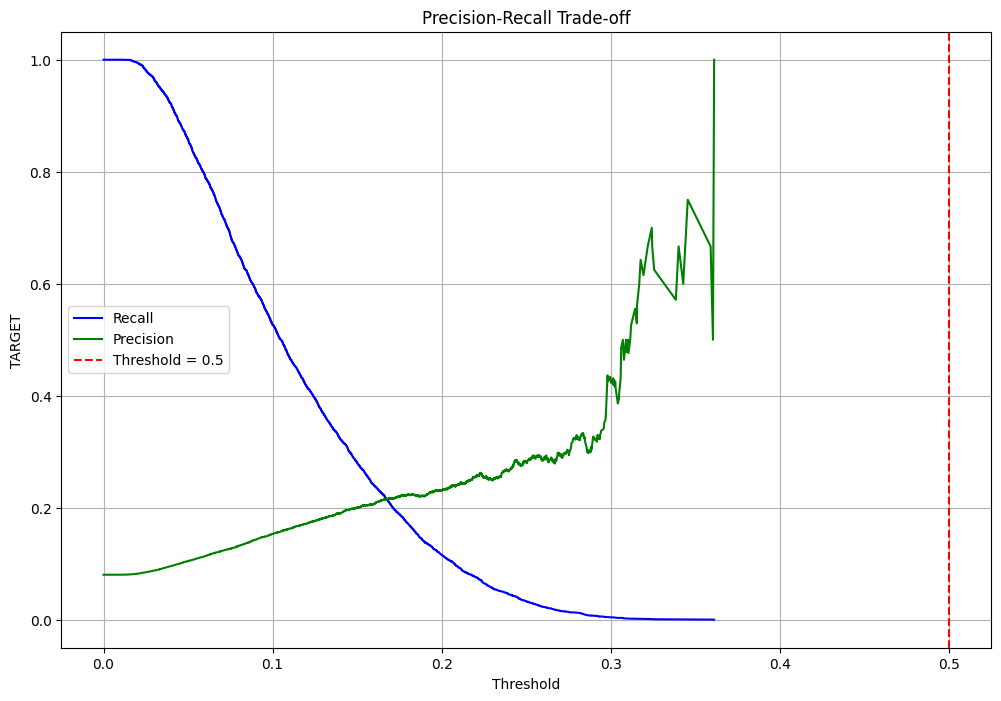

In [416]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

y_prob = final_lr.predict_proba(x_test_lr)[:,1]

precision, recall, thresholds = precision_recall_curve(y_test_lr, y_prob)

plt.figure(figsize=(12, 8))
plt.plot(thresholds, recall[:-1], label='Recall', color='blue')
plt.plot(thresholds, precision[:-1], label='Precision', color='green')
plt.xlabel('Threshold')
plt.ylabel('TARGET')
plt.title('Precision-Recall Trade-off')
plt.axvline(x=0.5, color='red', linestyle='--', label='Threshold = 0.5')
plt.legend()
plt.grid(True)
plt.show()

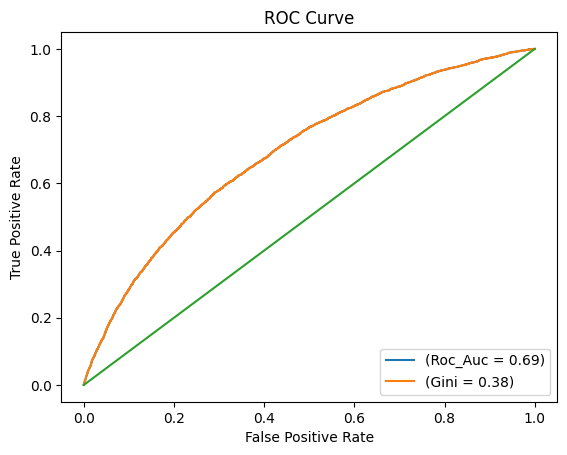

In [415]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve

y_prob = final_lr.predict_proba(x_test_lr)[:,1]

roc_auc = roc_auc_score(y_test_lr, y_prob)
gini = (2*roc_auc_score(y_test_lr, y_prob))-1

fpr, tpr, thresholds = roc_curve(y_test_lr, y_prob)
plt.figure()

plt.plot(fpr, tpr, label='(Roc_Auc = %0.2f)' % roc_auc)
plt.plot(fpr, tpr, label='(Gini = %0.2f)' % gini)
plt.plot([0, 1], [0, 1])
plt.xlim()
plt.ylim()

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend(loc='lower right')
plt.show()